<a href="https://colab.research.google.com/github/Emelygabrielaa/calgary-building-permits-eda/blob/main/notebooks/02_q1_processing_time.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project: Calgary Building Permits, Descriptive Analysis and EDA**

**Path:** Statistician path, Project 1 of 11  
**Question:** 1 of 5, Processing time (how long do applications take?)  
**Author:** Emely Rodriguez  
**Languages:** Python (lead), R (cross-check in a separate notebook)  
**Data as of:** 2026-10-27 snapshot, processed dataset (502,814 rows, 46 columns).   
**Licence:** Contains information licensed under the Open Government Licence - City of Calgary.

## Project phases

| Phase | Content | Status |
|---|---|---|
| 0. Data audit | Structure, quality and definitions of the source data | Done |
| 1. Analysis dataset | Handling of audit issues, selected columns, derived variables, dated snapshot | Done |
| **2. Analysis** | **Part A (descriptive) and Part B (formal tests and models), one notebook per question** | **This notebook (Question 1)** |
| 3. Report | Findings and conclusions | Pending |

## What this project is about
The City of Calgary publishes its building permit application records, which start in June 1999. In this project I use that table to answer five practical questions: how long applications take, how much the projects are worth, how activity changes over time, where it happens, and how complete the data is. In each question's notebook, Part A answers it with descriptive statistics and Part B follows with formal tests and models.

## The five questions

| # | Topic | Question | Part A: descriptive | Part B: going deeper |
|---|---|---|---|---|
| **1** | **Processing time** | **How long do applications take?** | **Days from application to issue, with percentiles by permit type** | **Kruskal-Wallis with pairwise tests, and Kaplan-Meier curves** |
| 2 | Project cost | How much are the projects worth? | Skewness, log scale, tail, and summaries by class | Lognormal fit check, bootstrap intervals for medians, quantile regression |
| 3 | Volume over time | How does activity change over time? | Counts by year and month, seasonality plots | Decomposition, Mann-Kendall trend test, count regression |
| 4 | Geography | Where does it happen? | Counts and medians by community, and a map | Rates per community and Moran's I |
| 5 | Missingness | How complete is the data? | Missing rates by column and permit type | Chi-square tests and logistic regression of missingness |

This notebook covers Question 1 (in bold). The other questions are in their own notebooks.

## The data

- **Source:** City of Calgary Open Data portal, dataset "Building Permits" (ID c2es-76ed)
- **Provider:** The City of Calgary, Dev Business and Bldg Srvc
- **What a row is:** a building permit application record, identified by `permitnum` (unique, checked in section 0.2.1 of the Phase 0 notebook)
- **Coverage:** applications from 1999-06-22 onward, updated daily
- **Size:** about 503,000 rows and 30 columns in the portal. The processed dataset used here has 502,814 rows and 46 columns, built in Phase 1 from a snapshot of 21 columns.
- **File used:** `data/processed/building_permits_processed_2026-10-27.parquet` in the project repository (Phase 1)
- **Coordinates:** WGS84 (EPSG:4326), in degrees
- **Licence:** City of Calgary Open Data Terms (https://data.calgary.ca/d/Open-Data-Terms/u45n-7awa)


**Reproducibility note:** this notebook reads the processed dataset built in Phase 1, which is fixed, so the values do not change. The dataset was built from the portal snapshot of 2026-10-27. The handling decisions and the definitions of the variables are in the Phase 1 notebook, and this notebook does not query the portal.

## Pills for this project
**Board pills:** Descriptive/EDA, Group Comparison, Missing-data analysis, Trend analysis,
Regression analysis, Uncertainty analysis, Spatial

**Method pills:** percentiles, ecdf, skewness, log-transform, heavy-tails, kruskal-wallis,
multiple-comparisons, censoring, kaplan-meier, competing-risks, bootstrap, quantile-regression, seasonality,
decomposition, mann-kendall, count-regression, rates-per-area, morans-i, choropleth,
missing-rates, chi-square, logistic-regression, mar-vs-mcar

## Pills for this notebook
**Board pills:** Descriptive/EDA, Group Comparison, Trend analysis, Uncertainty analysis

**Method pills:** percentiles, ecdf, skewness, log-transform, heavy-tails, kruskal-wallis,
multiple-comparisons, censoring, kaplan-meier, competing-risks

----------

# **Phase 2, Question 1: Processing time**

**Question:** how long do applications take?

**Goal:** describe the time from application to issue (Part A), and then test how it differs between permit types and how it behaves for applications that have not been issued yet (Part B).

**Input:** the processed dataset built in Phase 1. The handling decisions and the definitions of the variables are in the Phase 1 notebook, and this notebook does not repeat them.

## Q1.0 Setup

This notebook has its own setup, so it can run without the other notebooks.

### Q1.0.1 Libraries and data address

In [1]:
# Import the libraries: web requests, file handling, and data tables
import io, requests, pandas as pd

# Date of the snapshot the processed dataset was built from
SNAP_DATE = "2026-10-27"

# Address of the processed dataset in the public repository (raw file)
PROCESSED_URL = ("https://raw.githubusercontent.com/Emelygabrielaa/"
                 "calgary-building-permits-eda/main/data/processed/"
                 f"building_permits_processed_{SNAP_DATE}.parquet")

In [2]:
import io, requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt

### Q1.0.2 Loading the processed dataset

In [3]:
# Download the processed dataset and read it as a table
r = requests.get(PROCESSED_URL, timeout=300)
r.raise_for_status()                                   # stop with an error if the download fails
df = pd.read_parquet(io.BytesIO(r.content))

# Check the size: it must be 502,814 rows and 46 columns
print(df.shape)
print("Unique permit numbers:", df["permitnum"].nunique())

(502814, 46)
Unique permit numbers: 502814


The processed dataset has 502,814 rows and 46 columns, with one row for each permit number, as built in Phase 1.

# **Part A: Descriptive analysis**

| Section | Topic | What it shows |
|---|---|---|
| Q1.1 | What is measured | Applications with a time to issue, by status group |
| Q1.2 | Overall distribution | Percentiles and skewness of the time to issue |
| Q1.3 | Same-day issues | Share issued on the day of application, by permit type and by year |
| Q1.4 | Time to issue by permit type | Percentiles and ECDF for the five permit types |
| Q1.5 | Time to issue over the years | Percentiles by year, for Residential Improvement and the other types |
| Q1.6 | Applications still waiting | Open applications with no issue date and how long they have waited |
| | Summary of Part A | Main results of Part A |

## Q1.1 What is measured

The time to issue is `days_to_issue`, defined in Phase 1: the number of whole days from the application date to the issue date. It is empty for applications without an issue date and for the one application issued before its application date. Because it exists only for issued applications, the first step is to count how many applications have it in each status group.

In [4]:
# Applications with and without a time to issue, by status group
has_time = df["days_to_issue"].notna()
tab = pd.DataFrame({
    "applications": df["status_group"].value_counts(),
    "with_time_to_issue": df.loc[has_time, "status_group"].value_counts(),
}).fillna(0).astype(int)

# Applications without it, and the share that has it
tab["without"] = tab["applications"] - tab["with_time_to_issue"]
tab["pct_with"] = (100 * tab["with_time_to_issue"] / tab["applications"]).round(1)

# Add a total row
tab.loc["Total"] = [tab["applications"].sum(), tab["with_time_to_issue"].sum(),
                    tab["without"].sum(), round(100 * tab["with_time_to_issue"].sum() / tab["applications"].sum(), 1)]
tab = tab.astype({"applications": int, "with_time_to_issue": int, "without": int})
print(tab.to_string())

                      applications  with_time_to_issue  without  pct_with
status_group                                                             
Cancelled or refused         15760                2592    13168      16.4
Closed after issue           12079               11981       98      99.2
Completed                   455111              454916      195     100.0
Issued, in progress          14277               14277        0     100.0
On hold                       2035                 112     1923       5.5
Open before issue             3552                  72     3480       2.0
Total                       502814              483950    18864      96.2


483,950 of the 502,814 applications (96.2%) have a time to issue. Almost all Completed (99.96%), Closed after issue (99.2%) and Issued, in progress (100%) applications have it. It is mostly missing in two groups, for different reasons: 13,168 of the 15,760 Cancelled or refused applications ended without being issued, and 5,403 applications in On hold and Open before issue are still waiting. The other 293 are Completed (195) or Closed after issue (98) applications with no issue date, flagged in Phase 1.

This is important for the rest of the notebook because the distribution in Part A describes only the applications that were issued. The applications that ended without issue and the ones still waiting are not in it, so it understates the waiting time of the full set. Part B handles them with Kaplan-Meier and cumulative incidence curves.

## Q1.2 Overall distribution

The distribution of `days_to_issue` is summarized with percentiles and with skewness, a measure of asymmetry.

In [5]:
# Time to issue of the issued applications
t = df["days_to_issue"].dropna()

# Summary statistics with percentiles, and skewness
pcts = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
summary = t.describe(percentiles=pcts).round(1)
summary["skewness"] = round(t.skew(), 2)
print(summary.to_string())

count       483950.00
mean            24.00
std             51.70
min              0.00
1%               0.00
5%               0.00
10%              0.00
25%              1.00
50%             14.00
75%             28.00
90%             49.00
95%             76.00
99%            204.00
max           4684.00
skewness        14.94


The median time to issue is 14 days, and the middle half of the applications falls between 1 and 28 days (25th and 75th percentiles). The mean is 24.0 days, 1.7 times the median, because of a long right tail: 10% of the applications take more than 49 days, 1% more than 204 days, and the longest takes 4,684 days (about 12.8 years). The skewness is 14.94, so the distribution is strongly skewed to the right and the median describes the typical application better than the mean. The 10th percentile is 0 days because 21.8% of the applications were issued on the same day.

### Q1.2.1 Histogram and normal curve

The histogram shows the applications issued within 120 days, one bar per day. The bar heights are the share of all issued applications that fall on each day. A normal (bell) curve with the same mean and standard deviation is drawn over it, to check whether the time to issue is normally distributed. The few applications that take longer than 120 days are not plotted, and their share is printed below the chart.

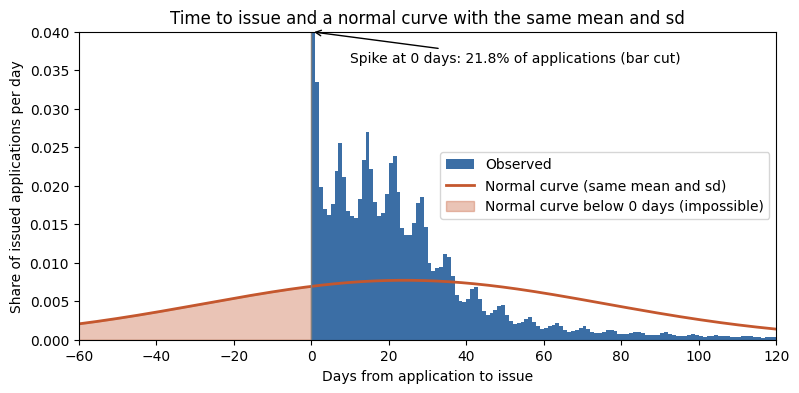

Normal curve below 0 days: 32.1%
Issued after 120 days: 11,484 applications (2.4%)


In [6]:
# Mean and standard deviation of the time to issue
mean, sd = t.mean(), t.std()

# Normal curve with the same mean and standard deviation, per day
x = np.linspace(-60, 120, 500)
normal = np.exp(-((x - mean) ** 2) / (2 * sd ** 2)) / (sd * np.sqrt(2 * np.pi))

# Histogram (share of all issued applications per day) and the normal curve
fig, ax = plt.subplots(figsize=(9, 4))
within = t[t <= 120]
ax.hist(within, bins=np.arange(0, 122), weights=np.full(len(within), 1 / len(t)),
        color="#3b6ea5", label="Observed")
ax.plot(x, normal, color="#c4572e", linewidth=2, label="Normal curve (same mean and sd)")
ax.fill_between(x[x < 0], normal[x < 0], color="#c4572e", alpha=0.35,
                label="Normal curve below 0 days (impossible)")
ax.axvline(0, color="grey", linewidth=1)

# Zoom the vertical axis and label the spike, which is cut at the top
same_day = (t == 0).mean()
ax.set_ylim(0, 0.04)
ax.annotate(f"Spike at 0 days: {100 * same_day:.1f}% of applications (bar cut)",
            xy=(0, 0.04), xytext=(10, 0.036), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-60, 120)
ax.set_xlabel("Days from application to issue")
ax.set_ylabel("Share of issued applications per day")
ax.set_title("Time to issue and a normal curve with the same mean and sd")
ax.legend(loc="center right")
plt.show()

# Share of the normal curve below zero days (impossible values), and share of data beyond 120 days
from math import erf, sqrt
below_zero = 0.5 * (1 + erf((0 - mean) / (sd * sqrt(2))))
print(f"Normal curve below 0 days: {100 * below_zero:.1f}%")
print(f"Issued after 120 days: {(t > 120).sum():,} applications ({100 * (t > 120).mean():.1f}%)")

The time to issue does not follow a normal distribution. A tall spike at 0 days holds 21.8% of the issued applications, followed by a lower and wider hump from 1 to about 40 days, with small peaks around 7, 14, 21 and 28 days that suggest review steps in whole weeks (the data does not say why). Another 11,484 applications (2.4%) take more than 120 days and are not shown. The normal curve with the same mean and standard deviation is very wide and low, and 32.1% of its area is below 0 days, which is impossible for a time to issue. With a spike at zero and a long right tail, the median and the percentiles describe the distribution better than the mean, and Part B uses rank-based tests such as Kruskal-Wallis instead of tests that assume normality.

### Q1.2.2 Empirical cumulative distribution (ECDF)

The ECDF shows, for each number of days, the share of issued applications issued within that time. The horizontal axis is linear up to 1 day and logarithmic beyond it, so the same-day issues and the long tail fit in one plot. The dotted lines mark the 50%, 90% and 99% levels.

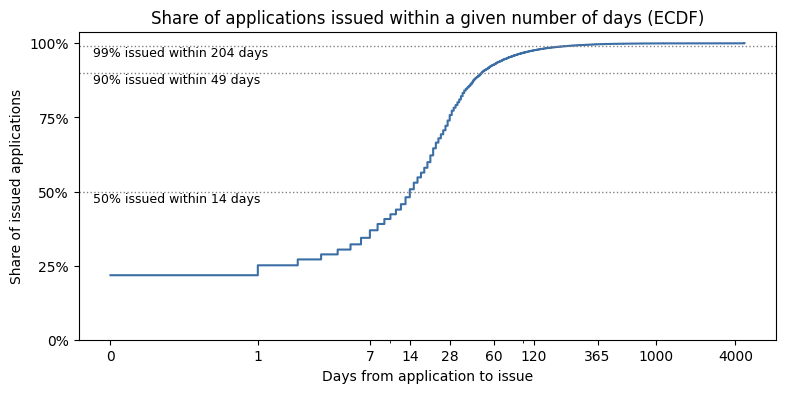

In [7]:
# ECDF from the number of applications issued on each day
counts = t.value_counts().sort_index()
days = counts.index.values
share = counts.cumsum().values / counts.sum()

# Plot with a scale that is linear up to 1 day and logarithmic after it
fig, ax = plt.subplots(figsize=(9, 4))
ax.step(days, share, where="post", color="#3b6ea5")
ax.set_xscale("symlog", linthresh=1)
ticks = [0, 1, 7, 14, 28, 60, 120, 365, 1000, 4000]
ax.set_xticks(ticks)
ax.set_xticklabels([str(v) for v in ticks])

# Dotted lines at 50%, 90% and 99%, each labelled with the number of days
for level in [0.50, 0.90, 0.99]:
    ax.axhline(level, color="grey", linestyle=":", linewidth=1)
    ax.text(0.02, level - 0.035, f"{int(level * 100)}% issued within {t.quantile(level):.0f} days",
            transform=ax.get_yaxis_transform(), fontsize=9)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Days from application to issue")
ax.set_ylabel("Share of issued applications")
ax.set_title("Share of applications issued within a given number of days (ECDF)")
plt.show()

The curve starts at 21.8% at 0 days, because of the same-day issues, and stays flat until 1 day. It then rises in steps at about 7, 14 and 28 days, matching the small peaks of the histogram, and reaches 50% at 14 days, 75% at 28 days, 90% at 49 days and 99% at 204 days. After about 120 days the curve is almost flat: the remaining 2.4% of the applications are spread over a long tail that reaches 4,684 days.

## Q1.3 Same-day issues

A time to issue of 0 days is a valid value, but it is common enough to change how the time to issue is described. This section shows where the same-day issues concentrate, by permit type and by year of application.

                                   issued  same_day  pct_same_day  pct_of_all_same_day
permittype                                                                            
Residential Improvement Project    216863    103290          47.6                 98.1
Commercial / Multi Family Project   95189       981           1.0                  0.9
Demolition                          16908       819           4.8                  0.8
Single Construction Permit         154373       210           0.1                  0.2
Environmental Restoration Permit      617         4           0.6                  0.0

All permit types: 105,304 of 483,950 (21.8%)


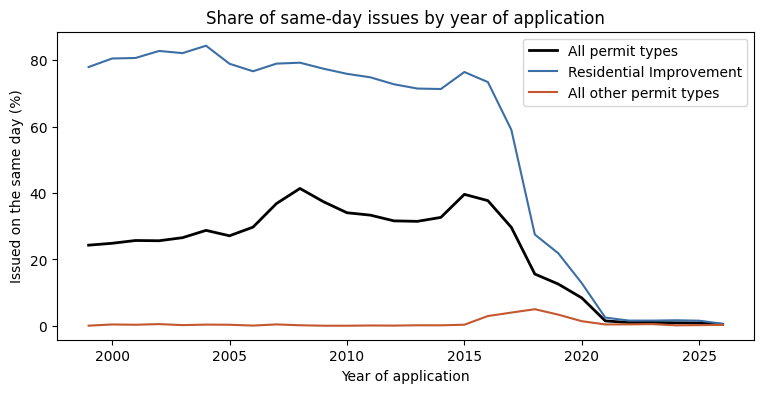

In [8]:
# Applications with a time to issue
issued = df[df["days_to_issue"].notna()]

# Same-day issues by permit type
by_type = issued.groupby("permittype")["issued_same_day"].agg(issued="size", same_day="sum")
by_type["pct_same_day"] = (100 * by_type["same_day"] / by_type["issued"]).round(1)
by_type["pct_of_all_same_day"] = (100 * by_type["same_day"] / by_type["same_day"].sum()).round(1)
print(by_type.sort_values("same_day", ascending=False).to_string())

# Total
total_same = int(by_type["same_day"].sum())
total_issued = int(by_type["issued"].sum())
print(f"\nAll permit types: {total_same:,} of {total_issued:,} ({100 * total_same / total_issued:.1f}%)")

# Share of same-day issues by year of application: all types, Residential Improvement, and all other types
is_ri = issued["permittype"] == "Residential Improvement Project"
def pct_by_year(d):
    return d.groupby("application_year")["issued_same_day"].mean().astype(float) * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pct_by_year(issued).index, pct_by_year(issued), color="black", linewidth=2, label="All permit types")
ax.plot(pct_by_year(issued[is_ri]).index, pct_by_year(issued[is_ri]), color="#3b6ea5", label="Residential Improvement")
ax.plot(pct_by_year(issued[~is_ri]).index, pct_by_year(issued[~is_ri]), color="#c4572e", label="All other permit types")
ax.set_xlabel("Year of application")
ax.set_ylabel("Issued on the same day (%)")
ax.set_title("Share of same-day issues by year of application")
ax.legend()
plt.show()

Of the 483,950 applications with a time to issue, 105,304 (21.8%) were issued on the same day, almost all of them in Residential Improvement projects: 47.6% of those applications were issued on the same day, and they account for 98.1% of all same-day issues. In the other permit types the share is small: 4.8% in Demolition, 1.0% in Commercial / Multi Family, 0.6% in Environmental Restoration and 0.1% in Single Construction Permit.

In [9]:
# Share of same-day issues by year of application, as a table
yearly = pd.DataFrame({
    "all_types": pct_by_year(issued),
    "residential_improvement": pct_by_year(issued[is_ri]),
    "other_types": pct_by_year(issued[~is_ri]),
}).round(1)
print(yearly.to_string())

                  all_types  residential_improvement  other_types
application_year                                                 
1999                   24.3                     77.9          0.1
2000                   24.9                     80.5          0.4
2001                   25.7                     80.7          0.3
2002                   25.6                     82.8          0.5
2003                   26.6                     82.1          0.2
2004                   28.8                     84.3          0.4
2005                   27.1                     78.9          0.3
2006                   29.7                     76.6          0.1
2007                   36.8                     78.9          0.4
2008                   41.4                     79.2          0.2
2009                   37.4                     77.4          0.1
2010                   34.1                     75.9          0.0
2011                   33.3                     74.8          0.1
2012      

The share of same-day issues changes a lot over the years. In Residential Improvement projects it stays between 71% and 84% from 1999 to 2016, then falls: 59.0% in 2017, 27.5% in 2018, 21.8% in 2019, 12.9% in 2020 and 2.5% in 2021, and it stays between 0.6% and 1.7% from 2022. For all permit types it goes from 24.3% in 1999 to a peak of 41.4% in 2008 (39.6% in 2015), and is about 1% since 2022. In the other permit types it is below 0.6% until 2015, peaks at 5.0% in 2018 and falls back to between 0.2% and 0.5% from 2021.

The data does not show whether the City changed its process or the way it records the issue date. Either way, the years before 2017 and after 2020 do not behave as one process, so the pooled distribution mixes two regimes, and section Q1.5 compares the years separately. The last point (2026) is a partial year.

## Q1.4 Time to issue by permit type


                                   issued   p25   p50    p75    p90    p95     p99   mean
permittype                                                                               
Residential Improvement Project    216863   0.0   1.0   12.0   32.0   56.0   167.0   13.6
Commercial / Multi Family Project   95189  13.0  21.0   42.0   85.0  134.0   320.0   40.7
Demolition                          16908   6.0  22.0   43.0   77.0  120.0   349.0   37.8
Single Construction Permit         154373  14.0  22.0   32.0   44.0   57.0   106.0   26.3
Environmental Restoration Permit      617  19.0  61.0  286.0  532.0  698.0  1043.0  183.7


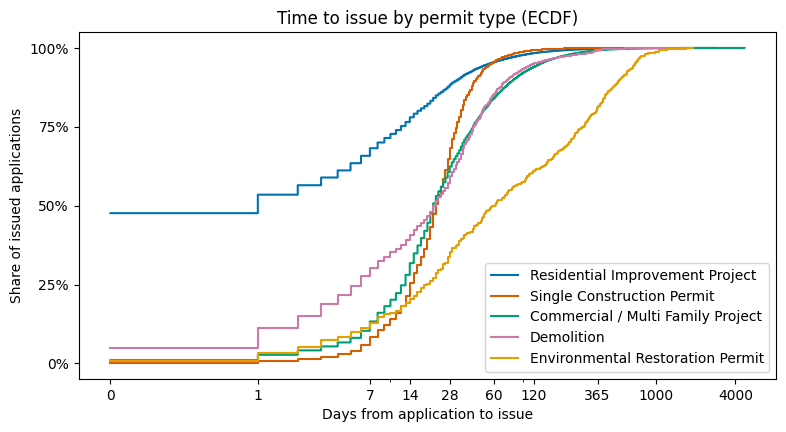

In [10]:
# Percentiles of the time to issue by permit type
pcts = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
grp = issued.groupby("permittype")["days_to_issue"]
pct_table = grp.quantile(pcts).unstack().round(0)
pct_table.columns = [f"p{int(q * 100)}" for q in pcts]

# Add the number of issued applications and the mean
pct_table.insert(0, "issued", grp.size())
pct_table["mean"] = grp.mean().round(1)
print(pct_table.sort_values("p50").to_string())

# ECDF of the time to issue for each permit type, on the same scale as before
colors = {"Residential Improvement Project": "#0072B2", "Single Construction Permit": "#D55E00",
          "Commercial / Multi Family Project": "#009E73", "Demolition": "#CC79A7",
          "Environmental Restoration Permit": "#E69F00"}

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, color in colors.items():
    counts = issued.loc[issued["permittype"] == name, "days_to_issue"].value_counts().sort_index()
    ax.step(counts.index.values, counts.cumsum().values / counts.sum(), where="post",
            color=color, label=name)

ax.set_xscale("symlog", linthresh=1)
ticks = [0, 1, 7, 14, 28, 60, 120, 365, 1000, 4000]
ax.set_xticks(ticks)
ax.set_xticklabels([str(v) for v in ticks])
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Days from application to issue")
ax.set_ylabel("Share of issued applications")
ax.set_title("Time to issue by permit type (ECDF)")
ax.legend(loc="lower right")
plt.show()

The five permit types have different profiles. Residential Improvement projects are the fastest: 47.6% are issued on the same day, the median is 1 day and 90% are issued within 32 days. Single Construction Permit is the most predictable: median 22 days, middle half between 14 and 32 days, and 99% within 106 days. Commercial / Multi Family and Demolition have almost the same median (21 and 22 days) but a longer tail: the 95th percentile is 134 and 120 days, against 57 in Single Construction Permit, and the 99th percentile is 320 and 349 days, against 106. Environmental Restoration is the slowest (median 61 days, 95th percentile 698 days), but it has only 617 issued applications, so its numbers are less stable.

The medians of Single Construction Permit, Commercial / Multi Family and Demolition differ by one day or less, and Part B tests formally whether the five types differ. These percentiles pool all the years, and the same-day issues in Residential Improvement were much more common before 2017 (section Q1.3), so the next section looks at the years.

## Q1.5 Time to issue over the years

The same-day issues of Residential Improvement projects change a lot over the years (section Q1.3), so the time to issue is shown by year of application for this type and for all the other permit types separately.

                 Residential Improvement                   All other types                  
                                     p25   p50   p75   p90             p25   p50   p75   p90
application_year                                                                            
1999                                 0.0   0.0   0.0   8.0            12.0  18.0  26.0  37.0
2000                                 0.0   0.0   0.0   5.0            10.0  15.0  23.0  36.0
2001                                 0.0   0.0   0.0   7.0            13.0  20.0  28.0  41.0
2002                                 0.0   0.0   0.0   4.0            16.0  23.0  34.0  48.0
2003                                 0.0   0.0   0.0   7.0            20.0  28.0  38.0  55.0
2004                                 0.0   0.0   0.0   6.0            20.0  28.0  36.0  51.0
2005                                 0.0   0.0   0.0   9.0            22.0  29.0  41.0  55.0
2006                                 0.0   0.0   0.0   7.0            

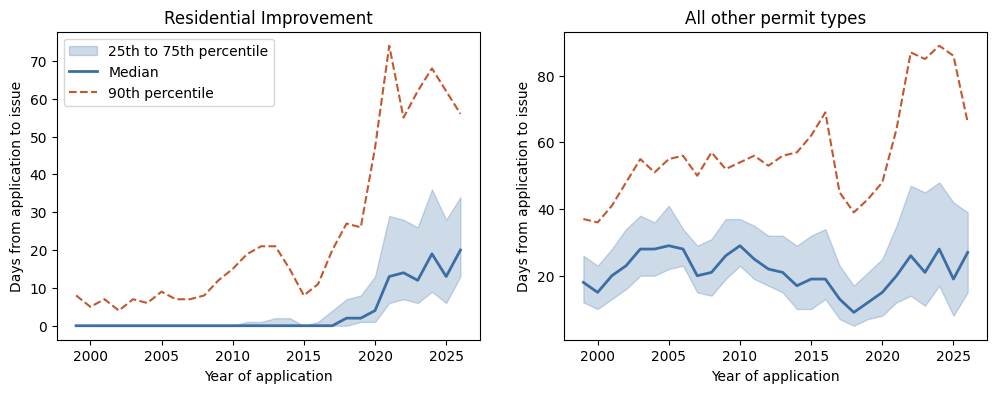

In [11]:
# Percentiles of the time to issue by year of application
def yearly_percentiles(d):
    out = d.groupby("application_year")["days_to_issue"].quantile([0.25, 0.5, 0.75, 0.9]).unstack()
    out.columns = ["p25", "p50", "p75", "p90"]
    return out

ri_year = yearly_percentiles(issued[is_ri])
other_year = yearly_percentiles(issued[~is_ri])

# Print both tables side by side
print(pd.concat({"Residential Improvement": ri_year, "All other types": other_year}, axis=1).round(0).to_string())

# One panel for each group
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title in zip(axes, [ri_year, other_year], ["Residential Improvement", "All other permit types"]):
    ax.fill_between(data.index, data["p25"], data["p75"], color="#3b6ea5", alpha=0.25, label="25th to 75th percentile")
    ax.plot(data.index, data["p50"], color="#3b6ea5", linewidth=2, label="Median")
    ax.plot(data.index, data["p90"], color="#c4572e", linestyle="--", label="90th percentile")
    ax.set_title(title)
    ax.set_xlabel("Year of application")
    ax.set_ylabel("Days from application to issue")
axes[0].legend()
plt.show()

The time to issue changes after 2016 and becomes longer in recent years. In Residential Improvement projects the median is 0 days in every year until 2017 and the 90th percentile stays between 4 and 21 days. From 2018 the median rises (2 days in 2018 and 2019, 4 in 2020), jumps to 13 days in 2021 and stays between 12 and 20 days since then, while the 90th percentile goes from 20 days in 2017 to between 55 and 74 days from 2021.

In the other permit types the median is between 15 and 29 days from 1999 to 2016 and the 90th percentile between 36 and 69 days. Both fall in 2017 to 2019 (median 13, 9 and 12 days). From 2021 the median returns to its earlier range (19 to 28 days), while the 90th percentile rises above it (64 to 89 days). Both groups change at about the same time, when the same-day issues of Residential Improvement almost disappear (section Q1.3).

Two cautions apply. Only issued applications are in these numbers, so applications from recent years that are still waiting are missing, and the recent percentiles understate the real waiting time. Part B addresses this with Kaplan-Meier curves. Also, 1999 and 2026 are partial years.

### Q1.5.1 Periods of application

**Decision.** The years are split into three periods, stored in the new column `period`:

| Period | Years |
|---|---|
| Before | 1999 to 2016 |
| Transition | 2017 to 2020 |
| Recent | 2021 to 2026 |

**Reasons:**
- The same-day issues of Residential Improvement projects stay between 71% and 84% until 2016, fall from 59% in 2017 to 13% in 2020, and stay below 3% from 2021. The percentiles of the time to issue change at the same time, in all permit types (section Q1.5).
- A pooled distribution mixes processes that do not behave in the same way, so Part B compares the types within each period.
- The periods come from the yearly results, so the comparisons by period are exploratory: they describe the change and do not test a hypothesis stated in advance.
- `period` is an analysis choice, so it lives in this notebook and not in the processed dataset of Phase 1.

In [12]:
# Period of application, from the year of application
df["period"] = pd.cut(df["application_year"], bins=[1998, 2016, 2020, 2026],
                      labels=["Before (1999-2016)", "Transition (2017-2020)", "Recent (2021-2026)"])

# Refresh the table of issued applications, so that it includes the new column
issued = df[df["days_to_issue"].notna()]
is_ri = issued["permittype"] == "Residential Improvement Project"

# Check the periods: applications, applications with a time to issue, same-day share and median
g = issued.groupby("period", observed=True)
summary = pd.DataFrame({
    "applications": df["period"].value_counts().sort_index(),
    "with_time_to_issue": g.size(),
    "same_day_pct": (g["issued_same_day"].mean().astype(float) * 100).round(1),
    "median_days": g["days_to_issue"].median(),
})
print(summary.to_string())
print("Applications without period:", df["period"].isna().sum())

                        applications  with_time_to_issue  same_day_pct  median_days
period                                                                             
Before (1999-2016)            297487              292631          31.8         14.0
Transition (2017-2020)         69666               67652          16.4          7.0
Recent (2021-2026)            135661              123667           1.0         19.0
Applications without period: 0


The three periods contain 297,487, 69,666 and 135,661 applications, and none is left without a period. The share with a time to issue falls from 98.4% before 2017 to 97.1% in the transition and 91.2% in the recent period, mainly because recent applications are still waiting. The median time to issue goes from 14 days to 7 and then to 19 days, while the share of same-day issues goes from 31.8% to 16.4% and 1.0%. The pooled median of 14 days hides this change.

## Q1.6 Applications still waiting

An open application with no issue date has an unknown final time to issue, which is at least the days it has waited so far. This section counts these applications and measures their wait up to the snapshot date (2026-10-27).

In [13]:
# Date of the snapshot, used to measure how long open applications have been waiting
SNAPSHOT_DATE = pd.Timestamp("2026-10-27")

# Applications still waiting: open before issue or on hold, with no issue date
waiting = df[df["status_group"].isin(["Open before issue", "On hold"]) & df["issueddate"].isna()].copy()
waiting["days_waiting"] = (SNAPSHOT_DATE - waiting["applieddate"]).dt.days

# Group the waiting time and count by status group
bins = [-1, 30, 90, 365, 3 * 365, 10000]
labels = ["up to 30 days", "31 to 90 days", "91 days to 1 year", "1 to 3 years", "more than 3 years"]
waiting["wait_group"] = pd.cut(waiting["days_waiting"], bins=bins, labels=labels)
print(pd.crosstab(waiting["wait_group"], waiting["status_group"], margins=True).to_string())

# Median and 90th percentile of the days waiting
print()
print(waiting["days_waiting"].describe(percentiles=[0.5, 0.9]).round(0).to_string())

status_group       On hold  Open before issue   All
wait_group                                         
up to 30 days          292               1406  1698
31 to 90 days          284                735  1019
91 days to 1 year      467                657  1124
1 to 3 years           440                499   939
more than 3 years      440                183   623
All                   1923               3480  5403

count    5403.0
mean      387.0
std       663.0
min         1.0
50%        89.0
90%      1229.0
max      5003.0


Of the 5,403 applications still waiting, 1,698 (31.4%) have waited 30 days or less, which is a normal queue. At the other end, 1,562 (28.9%) have waited more than one year and 623 (11.5%) more than three years. The median wait is 89 days, the 90th percentile is 1,229 days (about 3.4 years) and the longest is 5,003 days (about 13.7 years). Applications On hold wait longer than those Open before issue: 45.8% of them (880 of 1,923) have waited more than one year, against 19.6% (682 of 3,480). Since 99% of issued applications are issued within 204 days (section Q1.2), many long waits look like inactive applications, although the data does not confirm it.

## Summary of Part A

**What the EDA shows about the time to issue**

- **Typical time and shape.** Among the 483,950 issued applications (96.2%), the median is 14 days and the middle half falls between 1 and 28 days. The distribution is strongly skewed to the right: 21.8% are issued on the same day, 10% take more than 49 days and 1% more than 204 days. The median and the percentiles describe it better than the mean (24.0 days).
- **Permit type.** Residential Improvement is the fastest type (median 1 day, 47.6% issued on the same day). Single Construction Permit has a median of 22 days with a narrow spread. Commercial / Multi Family and Demolition have similar medians (21 and 22 days) but longer tails, and Environmental Restoration is the slowest (median 61 days, 617 issued applications).
- **Over time.** The same-day issues of Residential Improvement fall from between 71% and 84% until 2016 to below 3% from 2021, and the time to issue becomes longer in recent years. Three periods (1999 to 2016, 2017 to 2020 and 2021 to 2026) separate these regimes.
- **Applications still waiting.** 5,403 applications have no issue date and are still open, and 1,562 of them have waited more than one year, far beyond the usual time to issue.

**Limits of the EDA.** The distribution includes only issued applications. The 13,168 applications that ended without issue and the 5,403 still waiting are left out, so the waiting time of the full set is understated. The data does not explain the changes over time, and the periods come from looking at the yearly results.

**Next.** Part B tests whether the permit types differ in time to issue, and uses Kaplan-Meier curves to include the applications that are not issued yet.

# **Part B: Going deeper**

| Section | Content |
|---|---|
| Q1.7 Methods | The tests and curves used, and why |
| Q1.8 Survival variables | Follow-up time and status of each application |
| Q1.9 Kaplan-Meier and cumulative incidence | Curves overall, by permit type and by period |
| Q1.10 Kruskal-Wallis test and pairwise comparisons | Differences between permit types and their size |
| Q1.11 Sensitivity checks | Key results without the doubtful rows |
| Summary of Part B | What the formal methods add |

Part B extends the EDA of Part A. The EDA describes the time to issue and finds patterns, and Part B checks whether those patterns are real, how large they are, and how certain the estimates are.

| | Part A: EDA (main point) | Part B: extension |
|---|---|---|
| Purpose | Describe the data and find patterns | Check whether the patterns are real, how large, and how certain |
| Tools | Tables, percentiles, histograms, ECDF, yearly trends | Statistical tests, effect sizes, survival curves |
| Example in Question 1 | Residential Improvement has the shortest median time to issue | A test shows whether the permit types differ in time to issue and by how much |

Two points about the boundary between the parts. The Kaplan-Meier curves also describe the waiting time, including the applications that are not issued yet, but they need the censoring definitions and belong with the formal methods. And the periods were chosen after looking at the data (section Q1.5.1), so the comparisons by period stay exploratory, even in Part B.

## Q1.7 Methods

| Question | Method |
|---|---|
| Do the permit types differ in time to issue? | Kruskal-Wallis test, followed by pairwise tests with correction for multiple comparisons |
| How long do applications take when some are not issued yet? | Kaplan-Meier curves, and cumulative incidence curves for the applications that end without issue |

**Kruskal-Wallis and pairwise tests.** The Kruskal-Wallis test compares the time to issue across the five permit types using ranks, so it does not assume a normal distribution, which the time to issue does not follow (section Q1.2.1). A significant result says that at least one type differs, not which one, so pairwise tests follow (Dunn's test). Five types give ten pairs, and each test carries a chance of a false positive, so the p-values are corrected for multiple comparisons (Holm correction). With almost 484,000 issued applications even small differences are significant, so each p-value is reported with the size of the difference. The comparisons are made within each period (section Q1.5.1).

**Kaplan-Meier curves.** Some applications are not issued yet: their time to issue is unknown and is at least the days they have waited, so they are censored. Leaving them out understates the waiting time (section Q1.1), while the Kaplan-Meier estimator uses them up to the last day they are observed. The curves show the share of applications issued by each day. Applications that end without issue (Cancelled or refused) can no longer be issued, so they are a competing outcome, handled with cumulative incidence curves. The simple Kaplan-Meier curve, which treats them as censored, is shown for comparison. The curves complement the Kruskal-Wallis test, which uses only issued applications.

## Q1.8 Survival variables

Each application gets a follow-up time, `survival_days`, and a status, `survival_status`, counted from the application date:

| `survival_status` | Meaning | `survival_days` |
|---|---|---|
| 1 | Issued (also if cancelled later) | Days from application to issue |
| 2 | Ended without issue: Cancelled or refused with no issue date (competing outcome) | Days from application to the completion date |
| 0 | Still waiting: open or on hold with no issue date (censored) | Days from application to the snapshot date (2026-10-27) |
| Empty | Excluded: the time cannot be computed | Empty |

The excluded applications are those with a missing issue date that exists in reality (Completed and Closed after issue), those that ended without issue and have no end date, and one application whose end date is earlier than its application date.

In [14]:
# Groups of applications for the survival analysis
issued_ok = df["days_to_issue"].notna()
ended = (df["status_group"] == "Cancelled or refused") & df["issueddate"].isna() \
        & df["completeddate"].notna() & (df["completeddate"] >= df["applieddate"])
waiting = df["status_group"].isin(["Open before issue", "On hold"]) & df["issueddate"].isna()

# Status: 1 issued, 2 ended without issue, 0 still waiting, empty for the excluded
df["survival_status"] = np.select([issued_ok, ended, waiting], [1, 2, 0], default=-1)

# Follow-up time in days for each group
df["survival_days"] = np.select(
    [issued_ok, ended, waiting],
    [df["days_to_issue"], (df["completeddate"] - df["applieddate"]).dt.days,
     (SNAPSHOT_DATE - df["applieddate"]).dt.days],
    default=np.nan)

# Excluded applications get empty values
excluded = df["survival_status"] == -1
df.loc[excluded, ["survival_status", "survival_days"]] = np.nan

# Check the groups and the follow-up time of each
print(df["survival_status"].value_counts(dropna=False).to_string())
print("Total:", len(df))
print(df.groupby("survival_status")["survival_days"].describe().round(0).to_string())

survival_status
1.0    483950
2.0     13154
0.0      5403
NaN       307
Total: 502814
                    count   mean    std  min   25%   50%    75%     max
survival_status                                                        
0.0                5403.0  387.0  663.0  1.0  22.0  89.0  454.0  5003.0
1.0              483950.0   24.0   52.0  0.0   1.0  14.0   28.0  4684.0
2.0               13154.0  195.0  391.0  0.0   5.0  34.0  168.0  5275.0


The four groups add up to all 502,814 applications: 483,950 issued, 13,154 ended without issue, 5,403 still waiting and 307 excluded. The median follow-up is 14 days for issued applications, 34 days for those that ended without issue and 89 days for those still waiting. The last group is censored: its true time to issue is unknown and is at least the days waited so far.

## Q1.9 Kaplan-Meier and cumulative incidence

The curves use the `lifelines` library.

In [15]:
# Install the survival analysis library (needed once per Colab session)
!pip install lifelines -q

# Import the estimators for the curves
from lifelines import KaplanMeierFitter, AalenJohansenFitter

In [16]:
# Version check, to document the library used in the results
import lifelines
print("lifelines", lifelines.__version__)

lifelines 0.30.3


### Q1.9.1 Overall curve

A Kaplan-Meier curve uses the applications still waiting instead of dropping them. Here the event is the issue, and applications that ended without issue or are still waiting are censored at their last follow-up day. The curve shows the share issued by each day.

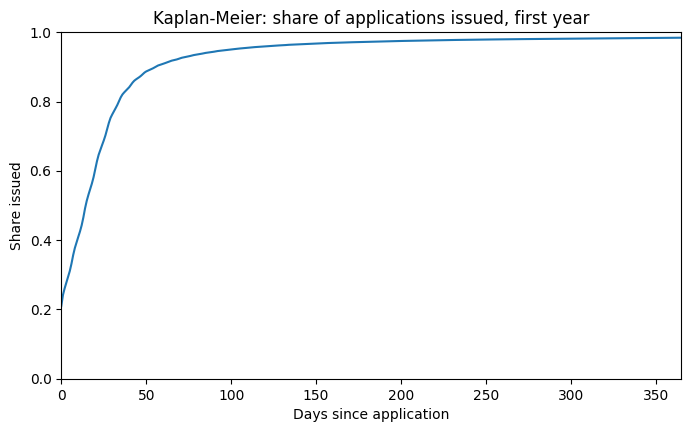

0      0.210
7      0.357
14     0.492
30     0.763
60     0.909
90     0.944
180    0.972
365    0.984
Median time to issue: 15.0


In [17]:
# Applications with a follow-up time (the 307 excluded are left out)
surv = df[df["survival_status"].notna()].copy()
surv["issued_event"] = (surv["survival_status"] == 1).astype(int)

# Kaplan-Meier fit: the event is the issue, all other outcomes are censored
kmf = KaplanMeierFitter()
kmf.fit(surv["survival_days"], event_observed=surv["issued_event"], label="All applications")

# Share issued by each day is 1 minus the survival function, with its confidence band
share = 1 - kmf.survival_function_["All applications"]
ci = kmf.confidence_interval_

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(share.index, share.values)
ax.fill_between(ci.index, 1 - ci.iloc[:, 1], 1 - ci.iloc[:, 0], alpha=0.2)
ax.set_xlim(0, 365)
ax.set_ylim(0, 1)
ax.set_xlabel("Days since application")
ax.set_ylabel("Share issued")
ax.set_title("Kaplan-Meier: share of applications issued, first year")
plt.show()

# Share issued at selected days and median time to issue
days = [0, 7, 14, 30, 60, 90, 180, 365]
print((1 - kmf.predict(days)).round(3).to_string())
print("Median time to issue:", kmf.median_survival_time_)

Half of the applications are issued within 15 days (median 15), 76.3% within 30 days and 90.9% within 60 days. At day 0 the curve starts at 21.0%, the same-day issues. After 90 days the curve is almost flat: 94.4% are issued by day 90 and 98.4% by day 365. The confidence band is too narrow to see with this number of applications. The median of 15 days is one day above the 14 days of Q1.2 because applications that are censored are not dropped here.

### Q1.9.2 Curves by permit type

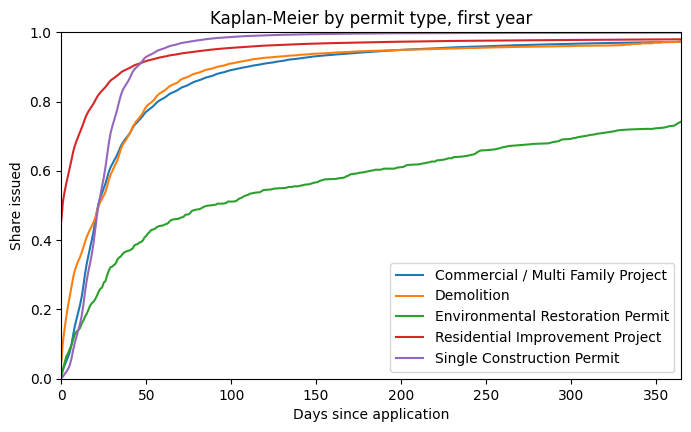

                                   issued by 7 d  issued by 30 d  issued by 90 d  issued by 365 d  median (days)
Commercial / Multi Family Project          0.126           0.620           0.876            0.972           22.0
Demolition                                 0.292           0.599           0.897            0.973           23.0
Environmental Restoration Permit           0.113           0.324           0.501            0.742           89.0
Residential Improvement Project            0.655           0.864           0.950            0.980            1.0
Single Construction Permit                 0.083           0.727           0.982            0.999           22.0


In [18]:
# One Kaplan-Meier curve per permit type, same event and censoring as the overall curve
fig, ax = plt.subplots(figsize=(8, 4.5))
days = [7, 30, 90, 365]
rows = {}

for name, g in surv.groupby("permittype"):
    km = KaplanMeierFitter().fit(g["survival_days"], g["issued_event"], label=name)
    ax.plot(km.timeline, 1 - km.survival_function_[name], label=name)
    # Share issued at selected days and median time to issue
    rows[name] = list((1 - km.predict(days)).round(3)) + [km.median_survival_time_]

ax.set_xlim(0, 365)
ax.set_ylim(0, 1)
ax.set_xlabel("Days since application")
ax.set_ylabel("Share issued")
ax.set_title("Kaplan-Meier by permit type, first year")
ax.legend(loc="lower right")
plt.show()

# Table with the share issued at each day and the median
table = pd.DataFrame(rows, index=[f"issued by {d} d" for d in days] + ["median (days)"]).T
print(table.to_string())

The curves differ in speed and shape. Residential Improvement starts fastest: 65.5% are issued within 7 days and the median is 1 day. Single Construction Permit starts slowest (8.3% by day 7) but rises steeply and overtakes the other types: 98.2% are issued by day 90 and 99.9% by day 365. Commercial / Multi Family and Demolition are close to each other, with medians of 22 and 23 days and about 97% issued by day 365. Environmental Restoration Permit is the clear exception: the median is 89 days and only 74.2% are issued after one year.

### Q1.9.3 Curves by period

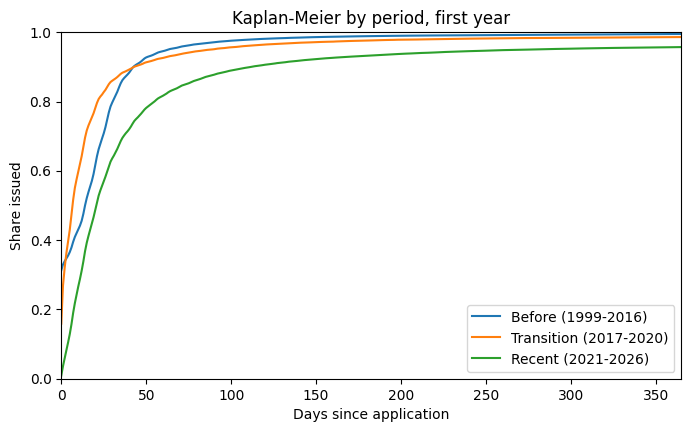

                        issued by 0 d  issued by 7 d  issued by 30 d  issued by 90 d  issued by 365 d  median (days)
Before (1999-2016)              0.313          0.395           0.797           0.971            0.995           14.0
Transition (2017-2020)          0.159          0.517           0.860           0.951            0.986            7.0
Recent (2021-2026)              0.009          0.190           0.636           0.877            0.957           21.0


In [19]:
# One Kaplan-Meier curve per period (surv gets the period column first)
surv["period"] = df.loc[surv.index, "period"]

fig, ax = plt.subplots(figsize=(8, 4.5))
days = [0, 7, 30, 90, 365]
rows = {}

for name, g in surv.groupby("period", observed=True):
    km = KaplanMeierFitter().fit(g["survival_days"], g["issued_event"], label=name)
    ax.plot(km.timeline, 1 - km.survival_function_[name], label=name)
    # Share issued at selected days and median time to issue
    rows[name] = list((1 - km.predict(days)).round(3)) + [km.median_survival_time_]

ax.set_xlim(0, 365)
ax.set_ylim(0, 1)
ax.set_xlabel("Days since application")
ax.set_ylabel("Share issued")
ax.set_title("Kaplan-Meier by period, first year")
ax.legend(loc="lower right")
plt.show()

# Table with the share issued at each day and the median
table = pd.DataFrame(rows, index=[f"issued by {d} d" for d in days] + ["median (days)"]).T
print(table.to_string())

The Recent curve is clearly lower than the other two. The median goes from 14 days (Before) to 7 (Transition) and 21 (Recent), and the share issued by day 365 goes from 99.5% to 98.6% and 95.7%. The Transition curve starts higher (51.7% issued by day 7 against 39.5%) but falls below the Before curve after about day 40. The Before curve starts at 31.3% at day 0, the same-day issues, while the Recent curve starts at 0.9%. These are the three regimes seen in Q1.5.

### Q1.9.4 Cumulative incidence by period

The cumulative incidence is the share of applications that had each outcome by a given day: issued, or ended without issue. Applications that end without issue are no longer waiting, so they cannot be issued later. This is the competing risk.

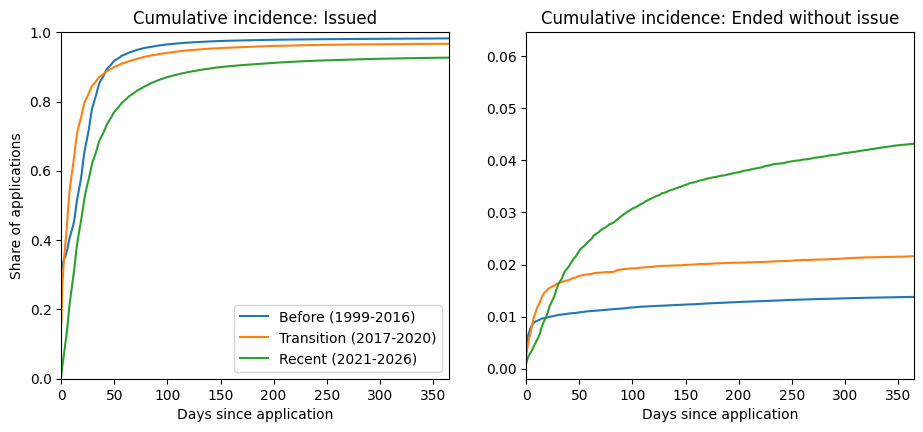

survival_days                               by 7 d  by 30 d  by 90 d  by 365 d
Before (1999-2016)     issued                0.394    0.790    0.961     0.982
                       ended without issue   0.009    0.010    0.012     0.014
Transition (2017-2020) issued                0.514    0.849    0.935     0.967
                       ended without issue   0.010    0.016    0.019     0.022
Recent (2021-2026)     issued                0.190    0.630    0.860     0.927
                       ended without issue   0.004    0.016    0.029     0.043


In [20]:
# Cumulative incidence of each outcome, exact with tied days
def cumulative_incidence(days, status):
    # Number of applications with each outcome (0 censored, 1 issued, 2 ended) on each day
    tab = pd.crosstab(days.astype(int), status.astype(int)).reindex(columns=[0, 1, 2], fill_value=0)
    # Applications still at risk at the start of each day
    at_risk = len(days) - tab.sum(axis=1).cumsum().shift(fill_value=0)
    d_issue, d_end = tab[1], tab[2]
    # Probability of no event of any kind before each day
    free_before = (1 - (d_issue + d_end) / at_risk).cumprod().shift(fill_value=1)
    # Cumulative incidence: probability of no event before the day times the outcome rate that day
    return (free_before * d_issue / at_risk).cumsum(), (free_before * d_end / at_risk).cumsum()

# Curves for each period, left issued, right ended without issue
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
days = [7, 30, 90, 365]
rows = {}

for name, g in surv.groupby("period", observed=True):
    issued_ci, ended_ci = cumulative_incidence(g["survival_days"], g["survival_status"])
    axes[0].plot(issued_ci.index, issued_ci.values, label=name)
    axes[1].plot(ended_ci.index, ended_ci.values, label=name)
    # Values at selected days (last known value up to each day)
    rows[(name, "issued")] = issued_ci.reindex(range(0, 366)).ffill().loc[days].round(3)
    rows[(name, "ended without issue")] = ended_ci.reindex(range(0, 366)).ffill().loc[days].round(3)

for ax, title in zip(axes, ["Issued", "Ended without issue"]):
    ax.set_xlim(0, 365)
    ax.set_xlabel("Days since application")
    ax.set_title(f"Cumulative incidence: {title}")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Share of applications")
axes[0].legend(loc="lower right")
plt.show()

# Table with the values at selected days
print(pd.DataFrame(rows).T.rename(columns=lambda d: f"by {d} d").to_string())

Counting the outcomes separately lowers the share issued. By day 365 it is 98.2% (Before), 96.7% (Transition) and 92.7% (Recent), against 99.5%, 98.6% and 95.7% in Q1.9.3, a drop of 1.3, 1.9 and 3.0 points. The share that ended without issue by day 365 grows from period to period: 1.4%, 2.2% and 4.3%. The rest, 0.4%, 1.1% and 3.0%, is still waiting after one year. The ordering of the periods does not change, so the simple curves tell the same story. The cumulative incidence is the correct one when the share issued is quoted.

## Q1.10 Kruskal-Wallis test and pairwise comparisons

The tests compare the time to issue between permit types. They need observed times, so only issued applications are used (483,950). A permit type needs at least 30 issued applications in a period to enter the comparisons of that period, because a smaller group cannot support a test or an effect size. Environmental Restoration Permit has 606 issued applications before 2017, 10 in the transition and 1 in the recent period, so it is compared only before 2017.

In [21]:
# Minimum number of issued applications for a permit type to enter the comparisons of a period
MIN_N = 30

# Short names for the five permit types, to keep the tables readable
short = {"Commercial / Multi Family Project": "Commercial", "Demolition": "Demolition",
         "Environmental Restoration Permit": "Environmental",
         "Residential Improvement Project": "Residential", "Single Construction Permit": "Single"}
issued = df[df["days_to_issue"].notna()].assign(type_short=lambda d: d["permittype"].map(short))

# Keep, in each period, only the permit types with at least MIN_N issued applications
size = issued.groupby(["period", "type_short"], observed=True)["days_to_issue"].transform("size")
tested = issued[size >= MIN_N]

# Applications that enter the comparisons (empty cell means the type is left out)
print(tested.groupby(["type_short", "period"], observed=True).size().unstack().to_string())
print("Applications in the comparisons:", len(tested), "of", len(issued))

period         Before (1999-2016)  Transition (2017-2020)  Recent (2021-2026)
type_short                                                                   
Commercial                56101.0                 15412.0             23676.0
Demolition                10147.0                  2380.0              4381.0
Environmental               606.0                     NaN                 NaN
Residential              120047.0                 34803.0             62013.0
Single                   105730.0                 15047.0             33596.0
Applications in the comparisons: 483939 of 483950


Environmental Restoration Permit is compared only before 2017. In the transition and recent periods it has 10 and 1 issued applications, below the minimum of 30, so it is left out of those periods. In total, 483,939 of the 483,950 issued applications enter the comparisons.

### Q1.10.1 Kruskal-Wallis test by period

The Kruskal-Wallis test checks whether the time to issue differs between permit types. It compares ranks, so the skewed distribution is not a problem. It is run for all years together and inside each period. With this many applications the p-value is almost always close to 0, so the effect size ε² (epsilon squared) shows how large the difference is: about 0.01 is small, 0.06 medium and 0.14 or more large.

In [22]:
# Kruskal-Wallis test on the applications that enter the comparisons
from scipy.stats import kruskal

samples = [("All periods", tested)] + list(tested.groupby("period", observed=True))

rows = []
for name, g in samples:
    # Time to issue of each permit type in this sample
    groups = [x["days_to_issue"].values for _, x in g.groupby("type_short")]
    h, p = kruskal(*groups)
    n = len(g)
    # Effect size: epsilon squared = H / (n - 1)
    rows.append({"sample": name, "n": n, "types": len(groups), "H": round(h, 1),
                 "p-value": "<0.001" if p < 0.001 else round(p, 3),
                 "epsilon2": round(h / (n - 1), 3)})

print(pd.DataFrame(rows).to_string(index=False))

                sample      n  types        H p-value  epsilon2
           All periods 483939      5 152824.0  <0.001     0.316
    Before (1999-2016) 292631      5 172693.0  <0.001     0.590
Transition (2017-2020)  67642      4  15020.0  <0.001     0.222
    Recent (2021-2026) 123666      4  16471.7  <0.001     0.133


The time to issue differs between permit types in all samples (p < 0.001), and the size of the difference changes a lot with the period. The effect size is large for all years together (ε² = 0.316), very large before 2017 (0.590), large in the transition (0.222) and medium in the recent period (0.133, just below the large threshold). Permit type explains less and less of the time to issue, which agrees with Q1.5: the same-day issues of Residential Improvement, the main reason for the differences, almost disappear from 2021.

### Q1.10.2 Dunn's test with Holm correction

Dunn's test compares every pair of permit types using the same ranks as the Kruskal-Wallis test. The Holm correction adjusts the p-values for the 10 comparisons made in each period. The library `scikit-posthocs` is needed.

In [23]:
# Install the library with Dunn's test (already installed in this session, quick to repeat)
!pip install scikit-posthocs -q
import scikit_posthocs as sp

# Dunn's test with Holm correction inside each period
dunn = {}
for name, g in tested.groupby("period", observed=True):
    dunn[name] = sp.posthoc_dunn(g, val_col="days_to_issue", group_col="type_short", p_adjust="holm")

# Pairs that stay above the 0.05 level after the correction
for name, m in dunn.items():
    pairs = [(a, b, round(float(m.loc[a, b]), 3)) for i, a in enumerate(m.index) for b in m.columns[i + 1:] if m.loc[a, b] >= 0.05]
    print(name, "| pairs not significant:", pairs if pairs else "none")

Before (1999-2016) | pairs not significant: [('Demolition', 'Environmental', 0.105)]
Transition (2017-2020) | pairs not significant: none
Recent (2021-2026) | pairs not significant: none


After the Holm correction, 9 of the 10 pairs differ before 2017, and all 6 pairs differ in the transition and in the recent period. The only pair that cannot be separated is Demolition and Environmental Restoration before 2017 (adjusted p = 0.105). This is not evidence that the two are equal, only that the test does not detect a difference with 606 Environmental Restoration applications.

### Q1.10.3 Pairwise effect size

For each pair, the effect size is the probability that a random application of the row type is issued faster than a random application of the column type. A value of 50% means no difference, and ties (same days) count as half. It is computed from the Mann-Whitney U statistic.


In [24]:
# Probability that a row type is issued faster than a column type, in each period
from scipy.stats import mannwhitneyu

effect = {}
for name, g in tested.groupby("period", observed=True):
    # Time to issue of each permit type that enters this period
    samples = {t: g.loc[g["type_short"] == t, "days_to_issue"].values for t in g["type_short"].unique()}
    types = sorted(samples)
    m = pd.DataFrame(np.nan, index=types, columns=types)
    for i, a in enumerate(types):
        for b in types[i + 1:]:
            # U counts the pairs where a is slower (ties count half), so 1 - U / (n_a * n_b) is the share where a is faster
            u = mannwhitneyu(samples[a], samples[b], method="asymptotic").statistic
            p_faster = 1 - u / (len(samples[a]) * len(samples[b]))
            m.loc[a, b], m.loc[b, a] = p_faster, 1 - p_faster
    effect[name] = m
    print(name, "(% chance that the row type is issued faster than the column type)")
    print((m * 100).round(0).to_string(na_rep=""), "\n")

Before (1999-2016) (% chance that the row type is issued faster than the column type)
               Commercial  Demolition  Environmental  Residential  Single
Commercial                       69.0           71.0          7.0    58.0
Demolition           31.0                       61.0          4.0    33.0
Environmental        29.0        39.0                         4.0    30.0
Residential          93.0        96.0           96.0                 94.0
Single               42.0        67.0           70.0          6.0         

Transition (2017-2020) (% chance that the row type is issued faster than the column type)
             Commercial  Demolition  Residential  Single
Commercial                     26.0         23.0    45.0
Demolition         74.0                     49.0    74.0
Residential        77.0        51.0                 78.0
Single             55.0        26.0         22.0         

Recent (2021-2026) (% chance that the row type is issued faster than the column type)
     

Before 2017, Residential Improvement is issued faster than every other type in 93% to 96% of the pairs. Then its lead shrinks. In the transition it is level with Demolition (51%) and ahead of Commercial and Single in about 77% of the pairs. In the recent period Demolition is the fastest type (75% to 88% against the others), Residential is second (73% against Commercial, 57% against Single) and Commercial is the slowest. The order of the other types also changes: Single is slower than Commercial before 2017 (42%) and faster from the transition onwards (55% and 71%). Environmental Restoration is slower than the other types before 2017 (29% to 39%), although the difference with Demolition is not significant (Q1.10.2). The ranking of permit types is not stable over time, which is the main finding of the formal tests.

## Q1.11 Sensitivity checks

The main results include some applications with doubtful data. This section repeats the key results without them, to see if the conclusions depend on those rows.

In [25]:
# How the two flag columns are coded, with the number of rows in each value
for col in ["date_order_issue", "status_date_conflict"]:
    print(col)
    print(df[col].value_counts(dropna=False).to_string(), "\n")

date_order_issue
date_order_issue
none                        502781
completed before issued         31
issued before applied            1
completed before applied         1 

status_date_conflict
status_date_conflict
none                                      502609
issue date in open or hold status            184
completion date in issued status              19
completion date in open or hold status         2 



`date_order_issue` marks 33 applications with dates in the wrong order (31 completed before issued, 1 issued before applied and 1 completed before applied). `status_date_conflict` marks 205 applications where the status and the dates disagree (184 open or on hold with an issue date, 19 issued with a completion date and 2 open or on hold with a completion date). The two groups are very small compared with 502,814 applications, so large changes are not expected.


### Q1.11.1 Key results without the doubtful rows

Each variant removes one group of doubtful applications. The three measures are the ones used in Q1.9 and Q1.10: the median time to issue (Kaplan-Meier), the share issued by day 365 (cumulative incidence) and ε² of the Kruskal-Wallis test.


In [26]:
# Short permit type names in the survival table, for the Kruskal-Wallis step
surv["type_short"] = surv["permittype"].map(short)

# Groups of doubtful applications
long_wait = (surv["survival_status"] == 0) & (surv["survival_days"] > 1095)
order_issue = surv["date_order_issue"] != "none"
status_conflict = surv["status_date_conflict"] != "none"

# Each variant keeps the applications that are not in the removed groups
variants = {
    "Main": pd.Series(True, index=surv.index),
    "Without waits over 3 years": ~long_wait,
    "Without date order issues": ~order_issue,
    "Without status conflicts": ~status_conflict,
    "Without all three": ~(long_wait | order_issue | status_conflict),
}

# Key results of each variant inside each period
rows = []
for variant, keep in variants.items():
    for period, g in surv[keep].groupby("period", observed=True):
        # Median time to issue from the Kaplan-Meier curve
        median = KaplanMeierFitter().fit(g["survival_days"], g["issued_event"]).median_survival_time_
        # Share issued by day 365 from the cumulative incidence
        issued_ci, _ = cumulative_incidence(g["survival_days"], g["survival_status"])
        by_365 = issued_ci.reindex(range(0, 366)).ffill().loc[365]
        # Kruskal-Wallis on issued applications, types with at least MIN_N in the period
        gi = g[g["survival_status"] == 1]
        gi = gi[gi.groupby("type_short")["survival_days"].transform("size") >= MIN_N]
        h, _ = kruskal(*[x["survival_days"].values for _, x in gi.groupby("type_short")])
        rows.append({"variant": variant, "period": period, "n": len(g), "median (days)": median,
                     "issued by 365 d (%)": round(by_365 * 100, 1), "epsilon2": round(h / (len(gi) - 1), 3)})

print(pd.DataFrame(rows).to_string(index=False))

                   variant                 period      n  median (days)  issued by 365 d (%)  epsilon2
                      Main     Before (1999-2016) 297246           14.0                 98.2     0.590
                      Main Transition (2017-2020)  69651            7.0                 96.7     0.222
                      Main     Recent (2021-2026) 135610           21.0                 92.7     0.133
Without waits over 3 years     Before (1999-2016) 297211           14.0                 98.3     0.590
Without waits over 3 years Transition (2017-2020)  69516            7.0                 96.9     0.222
Without waits over 3 years     Recent (2021-2026) 135157           21.0                 93.0     0.133
 Without date order issues     Before (1999-2016) 297237           14.0                 98.2     0.590
 Without date order issues Transition (2017-2020)  69633            7.0                 96.7     0.222
 Without date order issues     Recent (2021-2026) 135606           21.0  

The results do not depend on the doubtful rows. In the main analysis and in every variant, the median time to issue is the same (14, 7 and 21 days) and ε² is the same (0.590, 0.222 and 0.133, with one change of 0.001 in the transition when all three groups are removed). The share issued by day 365 changes at most 0.3 points, and only when the waits over three years are removed (from 92.7% to 93.0% in the recent period). The date order issues and the status conflicts have almost no effect because there are very few of them. Removing the long waits raises the share issued slightly because those applications stay in the risk set without ever being issued.

## Summary of Part B

The formal methods confirm the descriptive findings of Part A and add what the percentiles could not show.

- **Follow-up.** Of 502,814 applications, 483,950 are issued, 13,154 end without issue, 5,403 are still waiting (censored at the snapshot date) and 307 are excluded because their time cannot be computed.
- **Overall curve.** Half of the applications are issued within 15 days, 76.3% within 30 days and 98.4% within one year.
- **Permit types.** Residential Improvement starts fastest (median 1 day) and Single Construction Permit starts slowest but reaches 99.9% by day 365. Environmental Restoration is the slowest (median 89 days, 74.2% issued after one year) and has only 11 applications after 2016.
- **Periods.** The share issued by day 365 falls from 98.2% (before 2017) to 96.7% (transition) and 92.7% (recent). The share that ends without issue grows from 1.4% to 2.2% and 4.3%. Counting these outcomes as a competing risk lowers the share issued by 1.3 to 3.0 points compared with the simple curves.
- **Differences between types.** The Kruskal-Wallis test finds differences in all periods, and the effect size falls from very large (ε² = 0.590) to large (0.222) and medium (0.133). After the Holm correction, 9 of the 10 pairs differ before 2017 and all pairs differ afterwards.
- **No stable ranking.** Residential Improvement is the fastest type before 2017, Demolition is level with it in the transition and is the fastest in the recent period.
- **Robustness.** Removing the waits over three years, the date order issues and the status conflicts changes the share issued by at most 0.3 points and leaves the medians and ε² unchanged.

The time to issue is not a fixed property of each permit type. It depends on the period, and the change of regime around 2017 to 2021 is the main result of Question 1.

## Conclusion of Question 1

#### **Question. How long does it take to issue a building permit in Calgary, and how does it change by permit type and over time?**

**Data.** 502,814 building permit applications from the City of Calgary open data portal (applications from July 1999 to September 2026, snapshot of 2026-10-27). 483,950 have been issued.

**Answer.** The median time from application to issue is 15 days (14 days among the issued applications), and 96.6% of the applications are issued within one year, while another 2.3% end without issue in that time. The pooled figure hides a change over time that is larger than the differences between permit types:

| Period of application | Applications | Same-day issues | Median time to issue (days) | Issued by day 365 | Ended without issue by day 365 |
|---|---|---|---|---|---|
| Before 2017 | 297,487 | 31.8% | 14 | 98.2% | 1.4% |
| 2017 to 2020 | 69,666 | 16.4% | 7 | 96.7% | 2.2% |
| 2021 to 2026 | 135,661 | 1.0% | 21 | 92.7% | 4.3% |

By permit type:

| Permit type | Applications | Same-day issues | Median time to issue (days) | Issued by day 365 | Ended without issue by day 365 |
|---|---|---|---|---|---|
| Residential Improvement Project | 226,823 | 47.6% | 1 | 95.9% | 2.7% |
| Single Construction Permit | 156,507 | 0.1% | 22 | 99.1% | 0.8% |
| Commercial / Multi Family Project | 101,057 | 1.0% | 22 | 94.5% | 3.5% |
| Demolition | 17,680 | 4.8% | 23 | 95.6% | 2.3% |
| Environmental Restoration Permit | 747 | 0.6% | 89 | 68.1% | 10.3% |

Same-day issues are a share of the issued applications. Residential Improvement is the largest type and the fast one, with almost half of its applications issued on the same day. Single Construction Permit has almost no same-day issues but is the most predictable, with 99.1% issued within a year. Environmental Restoration is small, slow and the most likely to end without issue, and it has only 11 issued applications after 2016. Permit types differ in every period, but their ranking changes: Residential Improvement is the fastest before 2017 and Demolition is the fastest from 2021.

**What it means.**
- A single average time to issue is not a reliable guide: the wait depends on the period and on the permit type.
- The same-day issues of Residential Improvement, which made most of the fast cases, almost disappear from 2021. This fits the rise in the median.
- 5,403 applications are still waiting, and 1,562 of them (28.9%) have waited more than one year. Many may be inactive applications, which is a point for review in the source data.
- The share of applications that end without issue triples between the first and the last period (1.4% to 4.3%).

**Limits.** The periods are chosen after looking at the data, so they describe the data and do not test a hypothesis. The data show when the change happens but not why: a change in the process, in the rules or in the way dates are recorded cannot be told apart here. 307 applications are excluded because their time cannot be computed, and the results for the recent years can still change as the applications still waiting are resolved.

**Next.** Question 2 looks at the estimated project cost, which will show if the permits that take longer are also the larger projects.